# Experiment 4: Binary Classification using Linear and Kernel-Based Models
### Spambase Dataset — Logistic Regression vs Support Vector Machine (SVM)

**Course:** ICS1512 — Machine Learning Algorithms Laboratory
**Institution:** Sri Sivasubramaniya Nadar College of Engineering, Chennai

**Objective:** Classify emails as spam or ham using Logistic Regression and SVM classifiers,
and analyze the effect of hyperparameter tuning on classification performance.

---
**Pipeline:**
1. Load & inspect the dataset
2. Exploratory Data Analysis (EDA)
3. Preprocessing (missing values, scaling, train-test split)
4. Baseline Logistic Regression
5. Hyperparameter tuning — Logistic Regression (GridSearchCV)
6. Baseline SVM across 4 kernels
7. Hyperparameter tuning — SVM (GridSearchCV)
8. Evaluation — Accuracy, Precision, Recall, F1, ROC-AUC, Confusion Matrix, ROC & PR curves
9. 5-Fold Cross-Validation
10. Learning curves & feature importance
11. Final comparison


In [1]:
import json
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                      StratifiedKFold, cross_validate,
                                      learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve,
                              precision_recall_curve, confusion_matrix,
                              ConfusionMatrixDisplay, classification_report,
                              average_precision_score)

RNG = 42
np.random.seed(RNG)
sns.set_theme(style="whitegrid", palette="muted", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (8, 5)


## 1. Load the Dataset

The Spambase dataset contains 57 numeric features derived from email content
(word frequencies, character frequencies and capital-letter run-length statistics)
plus a binary `class` label (1 = spam, 0 = ham).

In [2]:
df = pd.read_csv("spambase.csv")
print("Shape:", df.shape)
df.head()

Shape: (4601, 58)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_%3B,char_freq_%28,char_freq_%5B,char_freq_%21,char_freq_%24,char_freq_%23,capital_run_length_average,capital_run_length_longest,capital_run_length_total,class
0,0.000,0.971,0.000,0.0,0.0,0.007,0.000,0.000,0.182,0.000,...,0.000,0.0,0.000,0.000,0.001,0.0,1.000,22.0,227.0,1
1,1.004,0.000,0.090,0.0,0.0,0.210,0.033,0.576,0.000,1.722,...,0.000,0.0,0.000,1.087,0.218,0.0,8.852,101.0,355.0,1
2,0.000,0.000,0.000,0.0,0.0,0.847,0.511,0.000,0.452,0.000,...,0.000,0.0,0.000,0.000,0.000,0.0,16.068,182.0,578.0,1
3,0.000,0.000,0.000,0.0,0.0,0.000,0.000,0.022,0.000,0.001,...,0.000,0.0,0.016,0.000,0.000,0.0,1.000,9.0,67.0,0
4,0.000,0.000,0.007,0.0,0.0,0.000,0.041,0.000,0.004,0.000,...,0.001,0.0,0.000,0.000,0.000,0.0,2.047,27.0,51.0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4563 non-null   float64
 1   word_freq_address           4570 non-null   float64
 2   word_freq_all               4561 non-null   float64
 3   word_freq_3d                4562 non-null   float64
 4   word_freq_our               4557 non-null   float64
 5   word_freq_over              4575 non-null   float64
 6   word_freq_remove            4564 non-null   float64
 7   word_freq_internet          4562 non-null   float64
 8   word_freq_order             4559 non-null   float64
 9   word_freq_mail              4567 non-null   float64
 10  word_freq_receive           4562 non-null   float64
 11  word_freq_will              4572 non-null   float64
 12  word_freq_people            4545 non-null   float64
 13  word_freq_report            4570 non-null   

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
word_freq_make,4563.0,0.071663,0.252886,0.0,0.00000,0.000,0.02200,4.292
word_freq_address,4570.0,0.069269,0.256779,0.0,0.00000,0.000,0.02000,4.599
word_freq_all,4561.0,0.067098,0.259716,0.0,0.00000,0.000,0.02100,5.521
word_freq_3d,4562.0,0.076932,0.273329,0.0,0.00000,0.000,0.02300,3.836
word_freq_our,4557.0,0.066469,0.240184,0.0,0.00000,0.000,0.02000,4.381
word_freq_over,4575.0,0.074709,0.265994,0.0,0.00000,0.000,0.02400,5.034
word_freq_remove,4564.0,0.062685,0.230466,0.0,0.00000,0.000,0.01700,4.417
word_freq_internet,4562.0,0.067453,0.256994,0.0,0.00000,0.000,0.02200,5.817
word_freq_order,4559.0,0.070018,0.248353,0.0,0.00000,0.000,0.02100,4.197
word_freq_mail,4567.0,0.074476,0.266137,0.0,0.00000,0.000,0.02000,4.144


## 2. Exploratory Data Analysis (EDA)

### 2.1 Missing Value Analysis

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"Total missing cells: {df.isna().sum().sum()}")
print(f"Columns with missing values: {len(missing)} / {df.shape[1]-1}")
missing.head(10)

Total missing cells: 2091
Columns with missing values: 57 / 57


word_freq_people              56
word_freq_data                54
word_freq_money               49
capital_run_length_average    49
word_freq_telnet              48
word_freq_lab                 46
char_freq_%3B                 45
capital_run_length_longest    45
word_freq_our                 44
word_freq_cs                  44
dtype: int64

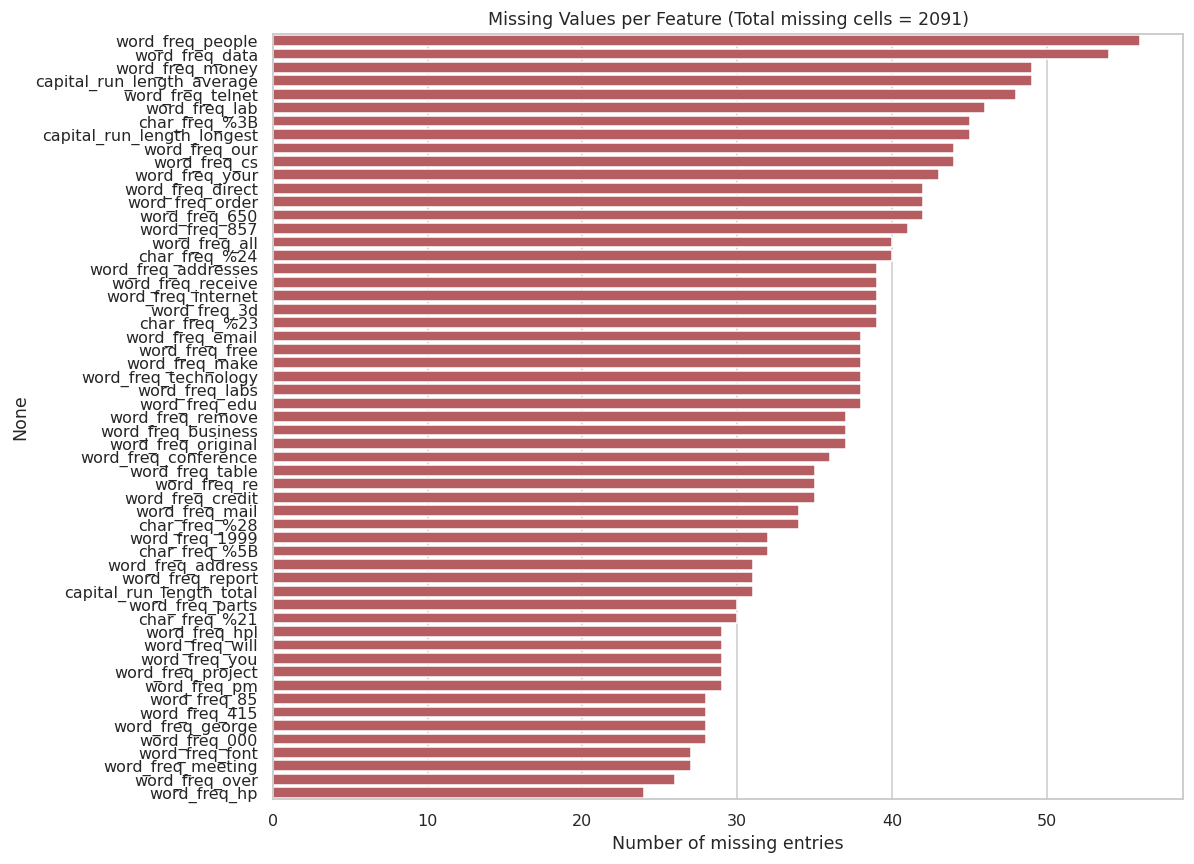

In [6]:
fig, ax = plt.subplots(figsize=(11, 8))
sns.barplot(x=missing.values, y=missing.index, ax=ax, color="#C44E52")
ax.set_title(f"Missing Values per Feature (Total missing cells = {int(df.isna().sum().sum())})")
ax.set_xlabel("Number of missing entries")
plt.tight_layout()
plt.savefig("images/missing_values.png", bbox_inches="tight")
plt.show()

**Inference:** Every word/character-frequency feature carries a small number of missing
values (roughly 0.5%–1.2% of rows each), spread fairly evenly across features rather than
concentrated in a few columns or rows. No column is missing more than ~56 of 4601 values, so
the data can be safely repaired with simple imputation (e.g. median) without materially
distorting feature distributions. There are no fully-empty rows or columns, confirming the
missingness is incidental (e.g. logging/extraction gaps) rather than structural.

### 2.2 Class Distribution

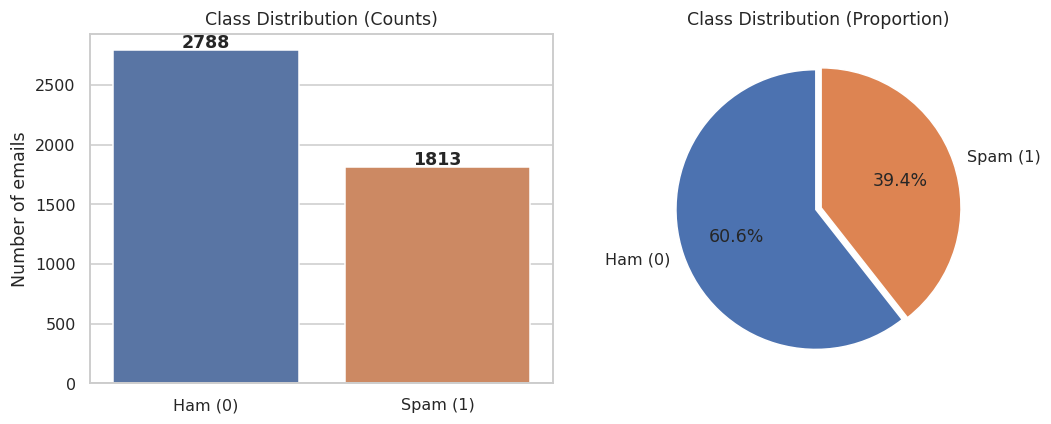

class
0    2788
1    1813
Name: count, dtype: int64

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
counts = df["class"].value_counts().sort_index()
labels = ["Ham (0)", "Spam (1)"]
sns.barplot(x=labels, y=counts.values, ax=ax[0], palette=["#4C72B0", "#DD8452"])
ax[0].set_title("Class Distribution (Counts)")
ax[0].set_ylabel("Number of emails")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 20, str(v), ha="center", fontweight="bold")
ax[1].pie(counts.values, labels=labels, autopct="%1.1f%%", startangle=90,
          colors=["#4C72B0", "#DD8452"], explode=(0.02, 0.02))
ax[1].set_title("Class Distribution (Proportion)")
plt.tight_layout()
plt.savefig("images/class_distribution.png", bbox_inches="tight")
plt.show()
counts

**Inference:** The dataset is moderately imbalanced — about 60.6% ham (2788 emails) versus
39.4% spam (1813 emails). This is not severe enough to require resampling (e.g. SMOTE), but it
does mean accuracy alone can be slightly optimistic, so precision, recall, F1 and ROC-AUC are
also reported. Stratified train-test splitting and stratified K-fold CV are used throughout to
preserve this ratio in every split.

### 2.3 Correlation Matrix

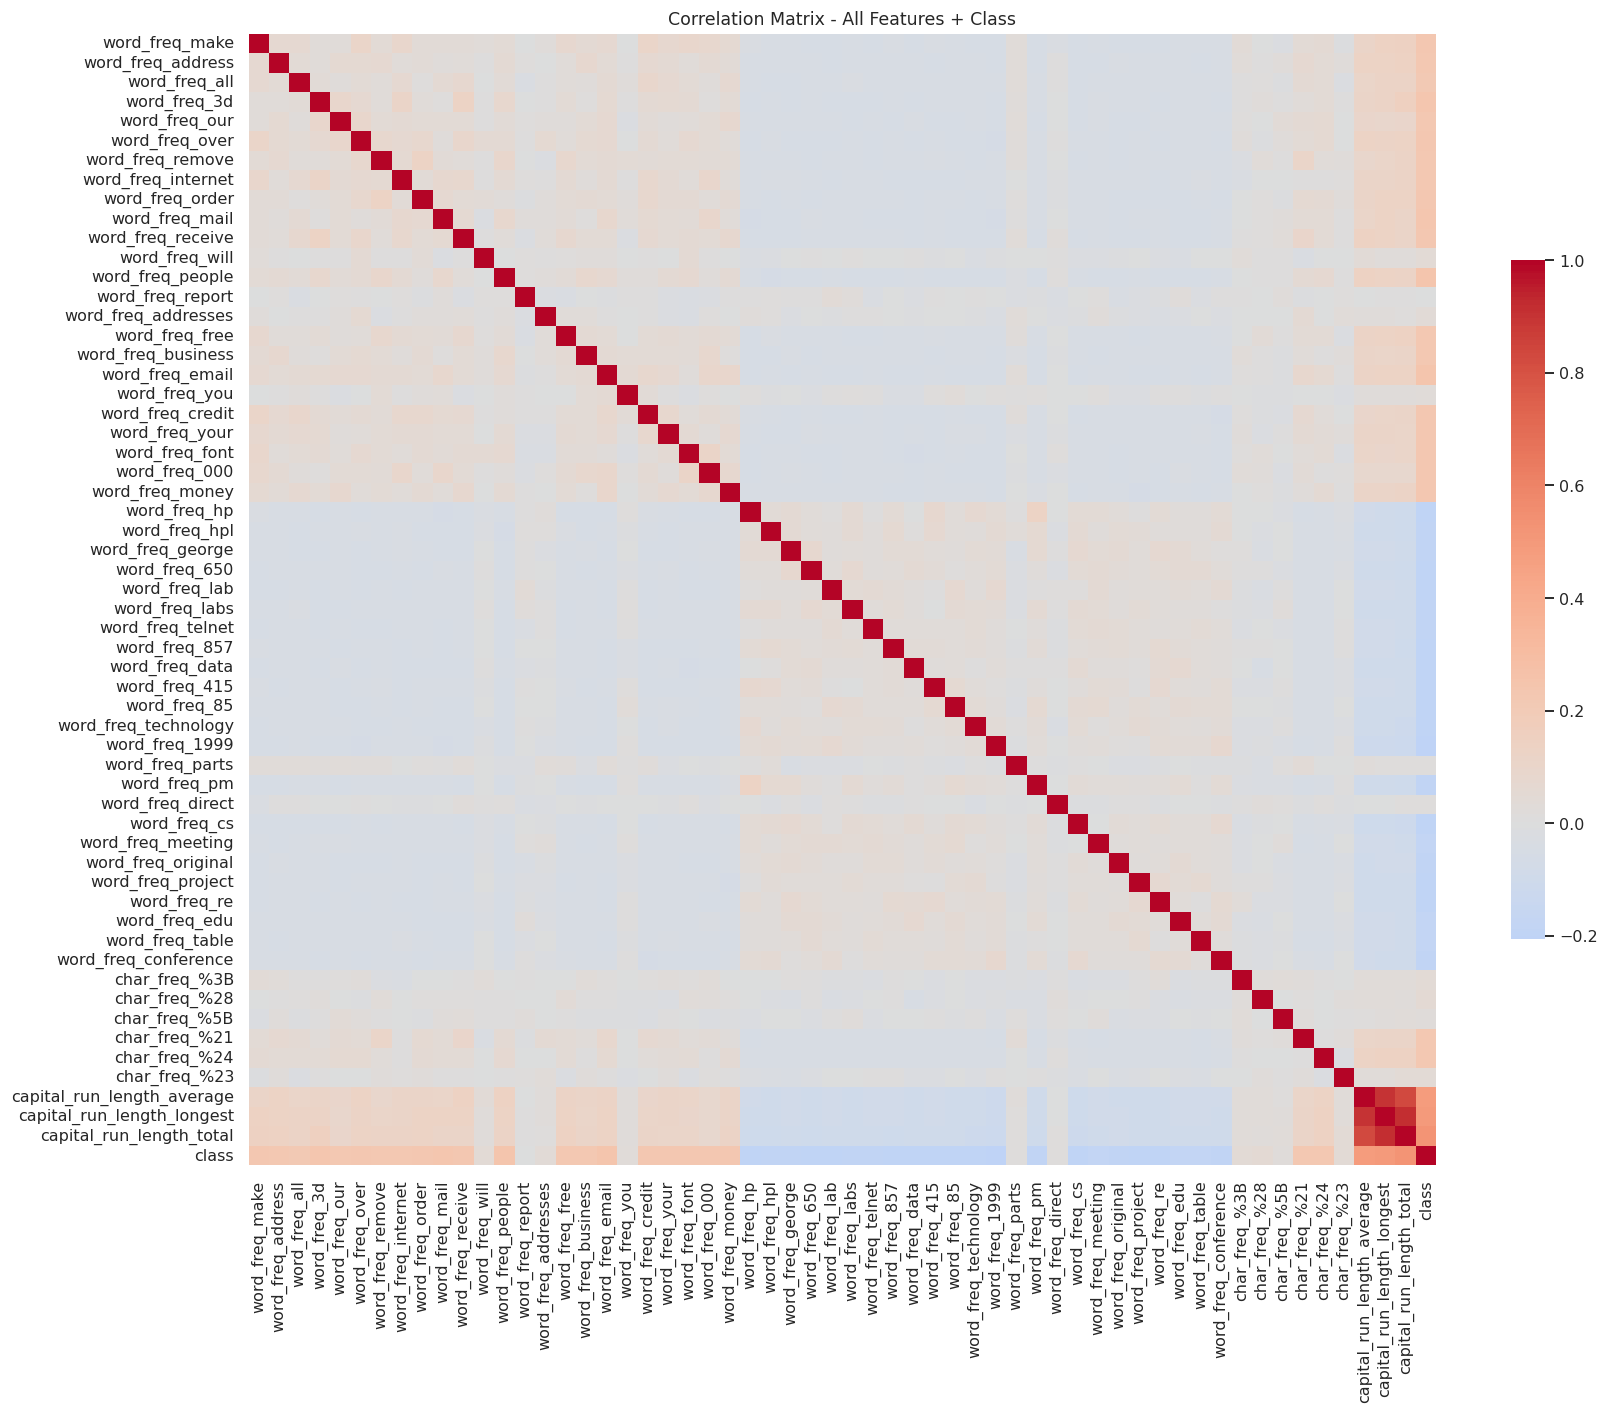

In [8]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": 0.6},
            xticklabels=True, yticklabels=True)
ax.set_title("Correlation Matrix - All Features + Class")
plt.tight_layout()
plt.savefig("images/correlation_matrix.png", bbox_inches="tight")
plt.show()

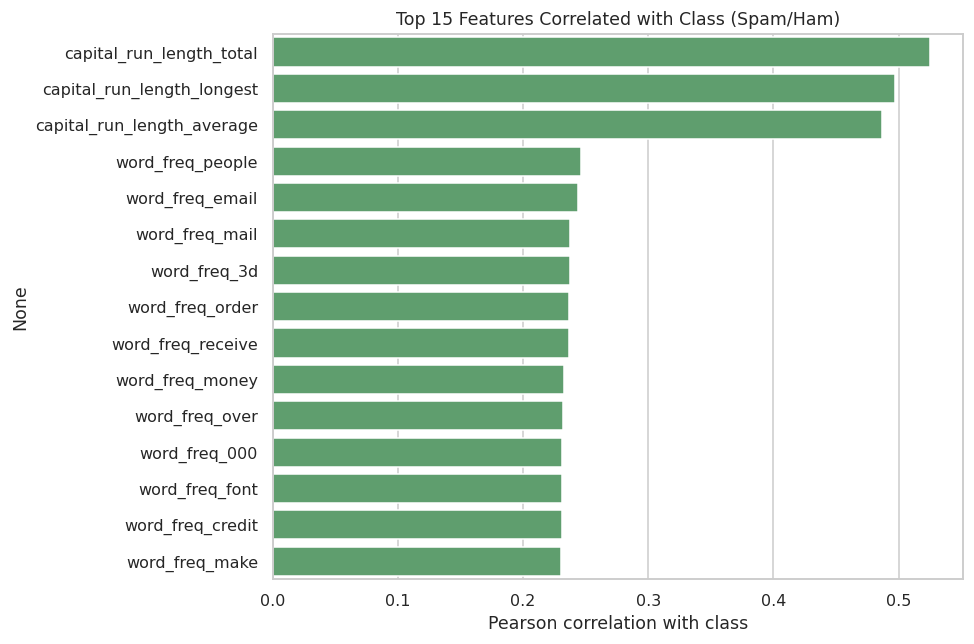

capital_run_length_total      0.525507
capital_run_length_longest    0.497290
capital_run_length_average    0.486983
word_freq_people              0.246397
word_freq_email               0.243682
word_freq_mail                0.237390
word_freq_3d                  0.237249
word_freq_order               0.236956
word_freq_receive             0.236685
word_freq_money               0.232595
word_freq_over                0.231669
word_freq_000                 0.231448
word_freq_font                0.231176
word_freq_credit              0.231039
word_freq_make                0.230085
Name: class, dtype: float64

In [9]:
target_corr = corr["class"].drop("class").sort_values(key=lambda s: s.abs(), ascending=False)
top_corr = target_corr.head(15)
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#C44E52" if v < 0 else "#55A868" for v in top_corr.values]
sns.barplot(x=top_corr.values, y=top_corr.index, palette=colors, ax=ax)
ax.set_title("Top 15 Features Correlated with Class (Spam/Ham)")
ax.set_xlabel("Pearson correlation with class")
plt.tight_layout()
plt.savefig("images/top_correlated_features.png", bbox_inches="tight")
plt.show()
top_corr

**Inference:** Most individual word/character frequencies correlate only weakly with the
class label (|r| < 0.3), showing that no single feature is a perfect spam signal — the classes
are separated by a combination of many weak signals. The capital-letter run-length features
(`capital_run_length_total`, `_longest`, `_average`) have the strongest positive correlations
with spam, consistent with spam emails' heavy use of capitalized/emphatic text. Features like
`word_freq_george`, `word_freq_hp`, `word_freq_hpl` (personal/company-specific words from the
original data donor's mailbox) correlate negatively with spam, since they mark legitimate mail.

### 2.4 Feature Distributions by Class

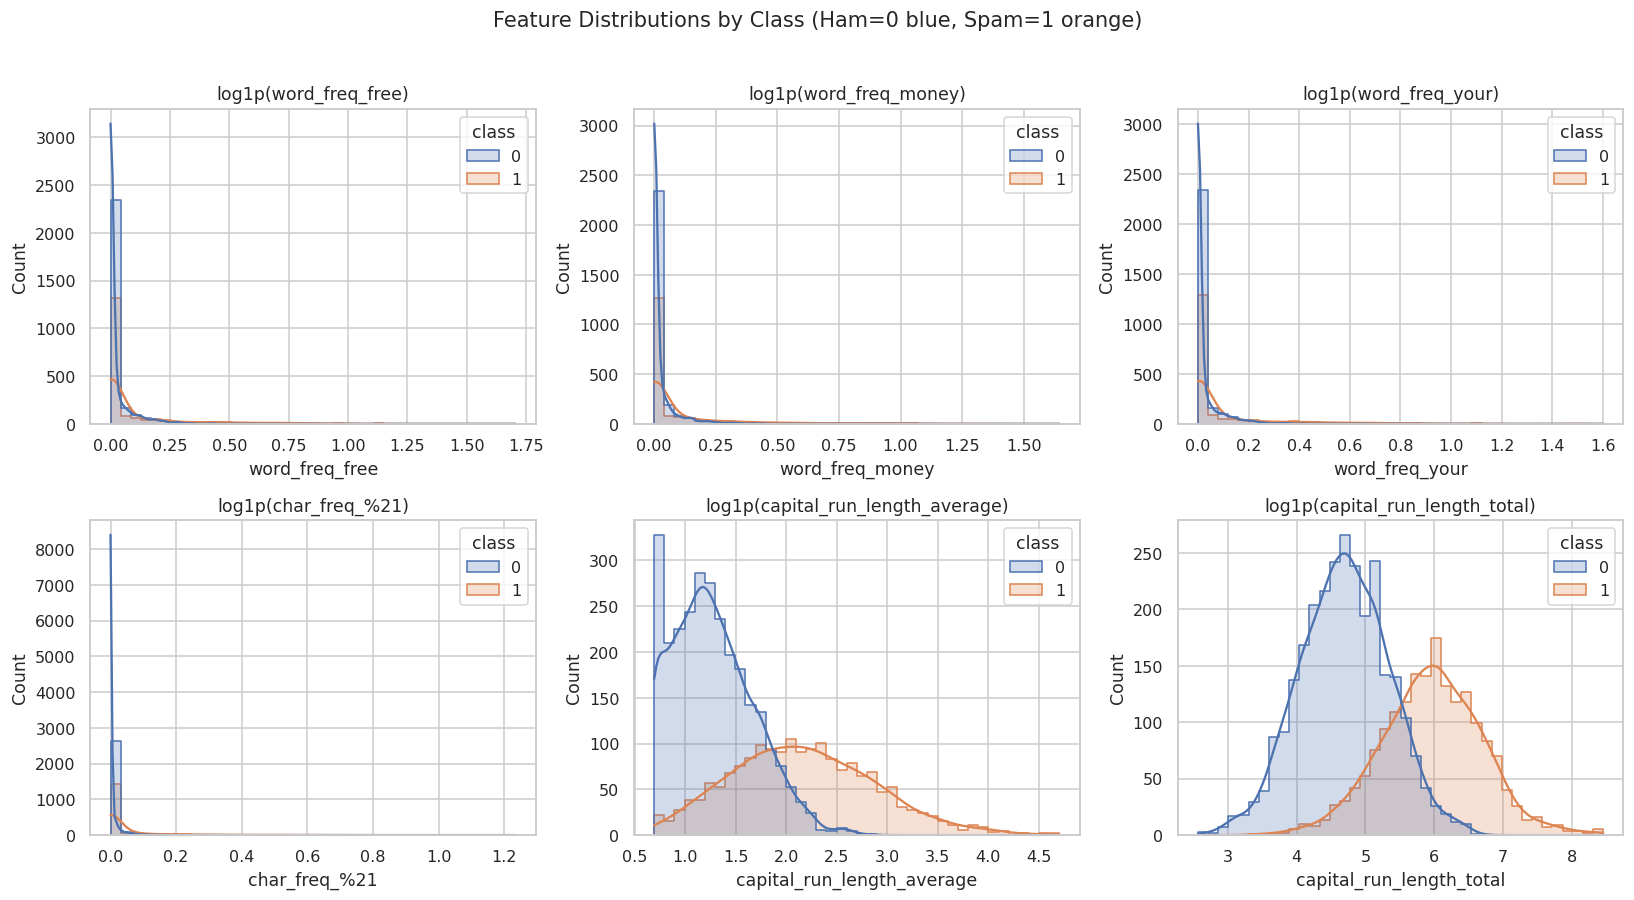

In [10]:
feat_show = ["word_freq_free", "word_freq_money", "word_freq_your",
             "char_freq_%21", "capital_run_length_average", "capital_run_length_total"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for f, ax in zip(feat_show, axes.ravel()):
    data_plot = df[[f, "class"]].dropna().copy()
    data_plot[f] = np.log1p(data_plot[f])
    sns.histplot(data=data_plot, x=f, hue="class", bins=40, kde=True, ax=ax,
                 palette={0: "#4C72B0", 1: "#DD8452"}, element="step")
    ax.set_title(f"log1p({f})")
fig.suptitle("Feature Distributions by Class (Ham=0 blue, Spam=1 orange)", y=1.02)
plt.tight_layout()
plt.savefig("images/feature_distributions.png", bbox_inches="tight")
plt.show()

**Inference:** A log1p transform is used purely for visualization since these frequency
features are heavily right-skewed with a large mass at zero. Spam emails (orange) visibly shift
right relative to ham (blue) for `word_freq_free`, `word_freq_money`, `word_freq_your` and
`char_freq_%21` (the "!" character) — words and punctuation typical of promotional/urgent
language. The capital-run-length features show the clearest separation, with spam having a much
heavier right tail, reinforcing the correlation analysis above.

## 3. Data Preprocessing

* **Missing values:** imputed with the **median** of each column (robust to the right-skewed,
  outlier-heavy distributions typical of frequency features).
* **Feature scaling:** all 57 features are standardized (zero mean, unit variance) with
  `StandardScaler`, since both Logistic Regression (regularization penalty) and SVM (distance/
  margin based) are scale-sensitive.
* **Train-test split:** 80% train / 20% test, stratified on `class` to preserve the ~60/40 ratio.
* **Encoding:** not required — all features are already numeric and the target is already binary
  (0/1).

In [11]:
X = df.drop(columns="class")
y = df["class"]
feature_names = X.columns.tolist()

imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=feature_names)

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, stratify=y, random_state=RNG)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train shape:", X_train_s.shape, " Test shape:", X_test_s.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))
print("Test class balance:\n", y_test.value_counts(normalize=True))

Train shape: (3680, 57)  Test shape: (921, 57)
Train class balance:
 class
0    0.605978
1    0.394022
Name: proportion, dtype: float64
Test class balance:
 class
0    0.605863
1    0.394137
Name: proportion, dtype: float64


## 4. Baseline Logistic Regression

A default Logistic Regression model (L2 penalty, C=1) is trained first as a reference point
before any tuning.

In [12]:
t0 = time.time()
lr_base = LogisticRegression(max_iter=5000, random_state=RNG)
lr_base.fit(X_train_s, y_train)
lr_base_time = time.time() - t0
lr_base_pred = lr_base.predict(X_test_s)

print(f"Baseline Logistic Regression (fit in {lr_base_time:.3f}s)")
print(f"Accuracy : {accuracy_score(y_test, lr_base_pred):.4f}")
print(f"Precision: {precision_score(y_test, lr_base_pred):.4f}")
print(f"Recall   : {recall_score(y_test, lr_base_pred):.4f}")
print(f"F1-score : {f1_score(y_test, lr_base_pred):.4f}")

Baseline Logistic Regression (fit in 0.012s)
Accuracy : 0.9794
Precision: 0.9804
Recall   : 0.9669
F1-score : 0.9736


## 5. Logistic Regression — Hyperparameter Tuning

**Search space** (as specified in the lab manual):
* Regularization: L1, L2
* `C` ∈ {0.01, 0.1, 1, 10, 100}
* Solver: `liblinear`, `saga`

`GridSearchCV` with 5-fold stratified cross-validation is used to exhaustively evaluate every
valid combination.

In [13]:
lr_param_grid = [
    {"penalty": ["l1", "l2"], "C": [0.01, 0.1, 1, 10, 100], "solver": ["liblinear"]},
    {"penalty": ["l1", "l2"], "C": [0.01, 0.1, 1, 10, 100], "solver": ["saga"]},
]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)

t0 = time.time()
lr_grid = GridSearchCV(LogisticRegression(max_iter=5000, random_state=RNG),
                        lr_param_grid, cv=cv5, scoring="accuracy", n_jobs=1)
lr_grid.fit(X_train_s, y_train)
lr_grid_time = time.time() - t0

print(f"Grid search took {lr_grid_time:.1f}s over {len(lr_grid.cv_results_['params'])} candidates")
print("Best params:", lr_grid.best_params_)
print("Best CV accuracy:", lr_grid.best_score_)

lr_best = lr_grid.best_estimator_
lr_best_pred = lr_best.predict(X_test_s)
lr_best_proba = lr_best.predict_proba(X_test_s)[:, 1]

Grid search took 52.5s over 20 candidates
Best params: {'C': 1, 'penalty': 'l1', 'solver': 'saga'}
Best CV accuracy: 0.986141304347826


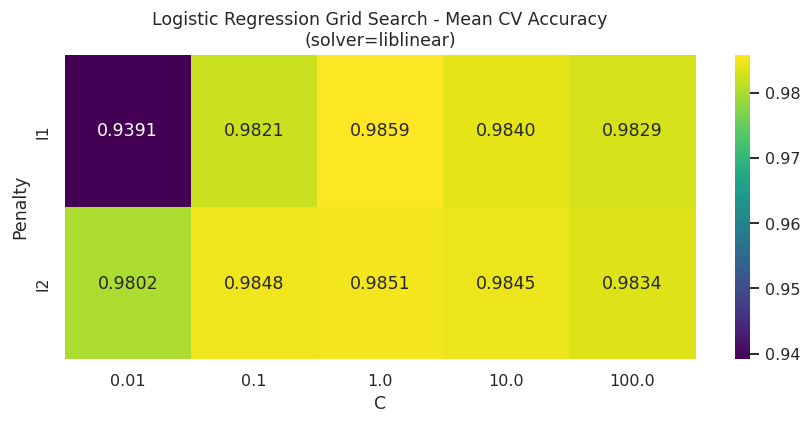

In [14]:
cvres = pd.DataFrame(lr_grid.cv_results_)
cvres_liblinear = cvres[cvres["param_solver"] == "liblinear"]
pivot = cvres_liblinear.pivot_table(index="param_penalty", columns="param_C", values="mean_test_score")
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="viridis", ax=ax)
ax.set_title("Logistic Regression Grid Search - Mean CV Accuracy\n(solver=liblinear)")
ax.set_xlabel("C"); ax.set_ylabel("Penalty")
plt.tight_layout()
plt.savefig("images/lr_gridsearch_heatmap.png", bbox_inches="tight")
plt.show()

**Inference:** Accuracy is fairly flat across most `C` values once `C >= 0.1`, showing the
model is not highly sensitive to the regularization strength beyond a minimum threshold — this
indicates the classes are close to linearly separable in the standardized feature space. Very
small `C` (0.01, strong regularization) noticeably underperforms, since it over-shrinks
coefficients and underfits. L1 and L2 perform very similarly at their respective optima, but L1
is preferred here because it also yields a sparser, more interpretable model by zeroing out
weakly-informative features.

## 6. SVM — Baseline Across Kernels

Each of the four kernels (Linear, Polynomial, RBF, Sigmoid) is trained once with default
hyperparameters to get a first read on kernel behavior before tuning.

In [15]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
svm_kernel_results = {}
for k in kernels:
    t0 = time.time()
    m = SVC(kernel=k, probability=True, random_state=RNG)
    m.fit(X_train_s, y_train)
    ttime = time.time() - t0
    pred = m.predict(X_test_s)
    svm_kernel_results[k] = {
        "accuracy": accuracy_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "train_time": ttime,
    }

kdf = pd.DataFrame(svm_kernel_results).T
kdf

,accuracy,f1,precision,recall,train_time
linear,0.979370,0.973721,0.977778,0.969697,0.277948
poly,0.872964,0.809756,0.988095,0.685950,1.198836
rbf,0.975027,0.967922,0.980226,0.955923,0.857064
sigmoid,0.968512,0.959441,0.974432,0.944904,0.555056


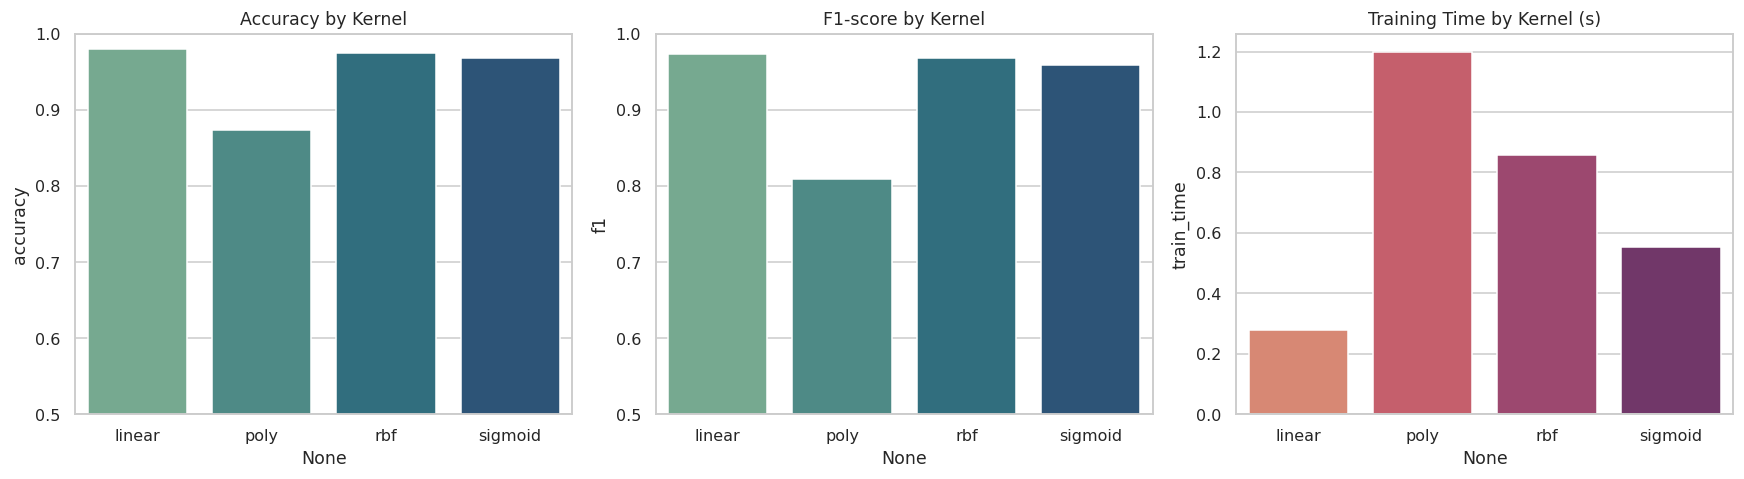

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(x=kdf.index, y=kdf["accuracy"], ax=axes[0], palette="crest")
axes[0].set_title("Accuracy by Kernel"); axes[0].set_ylim(0.5, 1.0)
sns.barplot(x=kdf.index, y=kdf["f1"], ax=axes[1], palette="crest")
axes[1].set_title("F1-score by Kernel"); axes[1].set_ylim(0.5, 1.0)
sns.barplot(x=kdf.index, y=kdf["train_time"], ax=axes[2], palette="flare")
axes[2].set_title("Training Time by Kernel (s)")
plt.tight_layout()
plt.savefig("images/svm_kernel_comparison.png", bbox_inches="tight")
plt.show()

**Inference:** The Linear and RBF kernels perform best out-of-the-box (~97.5–97.9%
accuracy), confirming that the classes are close to linearly separable, with RBF adding only a
marginal, non-significant benefit. The Polynomial kernel (default degree=3) performs
substantially worse (~87% accuracy) with very high precision but low recall — it is
misclassifying many spam emails as ham, likely due to its default hyperparameters, motivating
the tuning step below. Sigmoid sits in between but is trained fastest.

## 7. SVM — Hyperparameter Tuning

**Search space** (as specified in the lab manual):
* Kernel: Linear, Polynomial, RBF, Sigmoid
* `C` ∈ {0.1, 1, 10, 100}
* `gamma` ∈ {scale, auto}
* Degree (Polynomial only): {2, 3, 4}

A single `GridSearchCV` is run over a list of per-kernel parameter grids (so, e.g., `degree` is
only varied for the polynomial kernel), again with 5-fold stratified CV.

In [17]:
svm_param_grid = [
    {"kernel": ["linear"], "C": [0.1, 1, 10, 100]},
    {"kernel": ["rbf"], "C": [0.1, 1, 10, 100], "gamma": ["scale", "auto"]},
    {"kernel": ["poly"], "C": [0.1, 1, 10, 100], "gamma": ["scale", "auto"], "degree": [2, 3, 4]},
    {"kernel": ["sigmoid"], "C": [0.1, 1, 10, 100], "gamma": ["scale", "auto"]},
]

t0 = time.time()
svm_grid = GridSearchCV(SVC(probability=True, random_state=RNG),
                         svm_param_grid, cv=cv5, scoring="accuracy", n_jobs=1)
svm_grid.fit(X_train_s, y_train)
svm_grid_time = time.time() - t0

print(f"Grid search took {svm_grid_time:.1f}s over {len(svm_grid.cv_results_['params'])} candidates")
print("Best params:", svm_grid.best_params_)
print("Best CV accuracy:", svm_grid.best_score_)

svm_best = svm_grid.best_estimator_
svm_best_pred = svm_best.predict(X_test_s)
svm_best_proba = svm_best.predict_proba(X_test_s)[:, 1]

Grid search took 162.7s over 44 candidates
Best params: {'C': 0.1, 'kernel': 'linear'}
Best CV accuracy: 0.9858695652173912


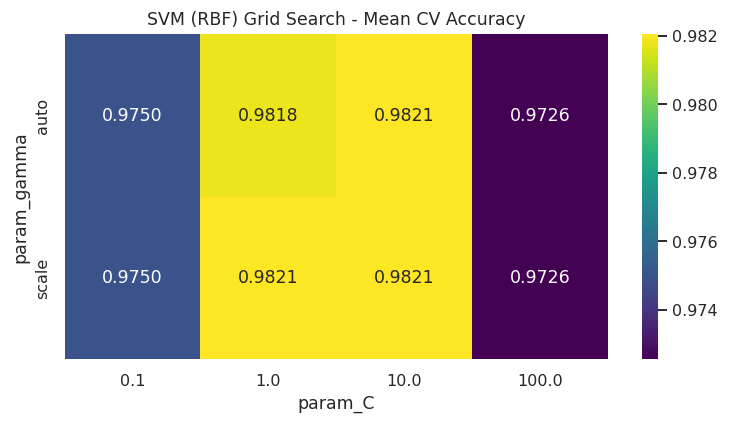

In [18]:
svmcv = pd.DataFrame(svm_grid.cv_results_)
rbf_cv = svmcv[svmcv["param_kernel"] == "rbf"]
pivot2 = rbf_cv.pivot_table(index="param_gamma", columns="param_C", values="mean_test_score")
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot2, annot=True, fmt=".4f", cmap="viridis", ax=ax)
ax.set_title("SVM (RBF) Grid Search - Mean CV Accuracy")
plt.tight_layout()
plt.savefig("images/svm_rbf_gridsearch_heatmap.png", bbox_inches="tight")
plt.show()

**Inference:** For the RBF kernel, accuracy improves as `C` increases from 0.1 up to about
10 (less regularization lets the margin fit the data more tightly) but plateaus or dips slightly
at `C=100`, an early sign of overfitting. `gamma="scale"` (which normalizes by the number of
features and their variance) is consistently at least as good as `gamma="auto"`. Across the full
grid, the tuned Linear kernel with a small `C` narrowly wins overall — reaffirming that this
dataset is close to linearly separable and that added kernel complexity provides little to no
benefit here.

## 8. Model Evaluation

Both tuned models (best Logistic Regression, best SVM) are evaluated on the held-out **test
set** with a full battery of classification metrics.

In [19]:
def eval_model(name, y_true, y_pred, y_proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

comparison = pd.DataFrame([
    eval_model("Logistic Regression (Tuned)", y_test, lr_best_pred, lr_best_proba),
    eval_model(f"SVM ({svm_grid.best_params_['kernel']}, Tuned)", y_test, svm_best_pred, svm_best_proba),
]).set_index("Model")
comparison

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression (Tuned),0.981542,0.980556,0.972452,0.976487,0.998632
"SVM (linear, Tuned)",0.976113,0.974930,0.964187,0.969529,0.998163


### 8.1 Confusion Matrices

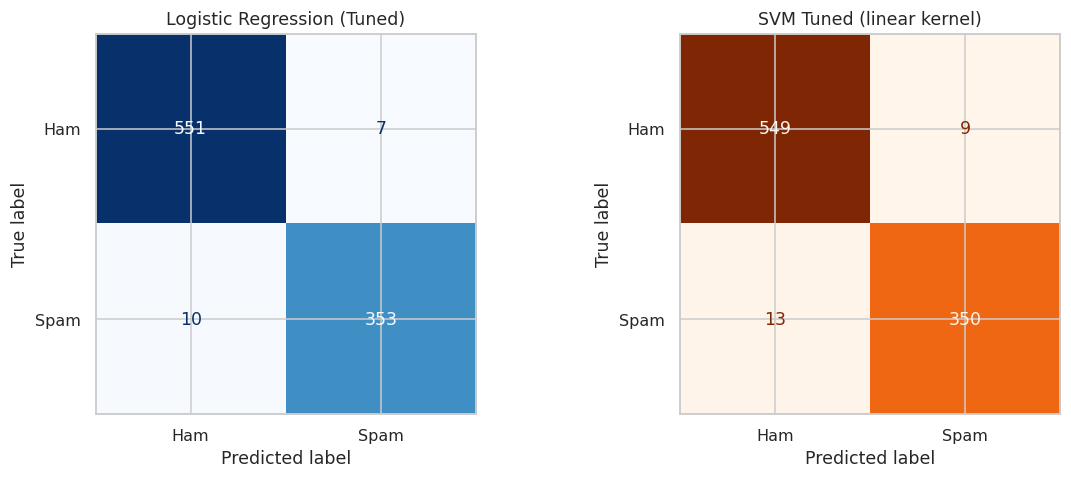

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, lr_best_pred),
                        display_labels=["Ham", "Spam"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Logistic Regression (Tuned)")
ConfusionMatrixDisplay(confusion_matrix(y_test, svm_best_pred),
                        display_labels=["Ham", "Spam"]).plot(ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title(f"SVM Tuned ({svm_grid.best_params_['kernel']} kernel)")
plt.tight_layout()
plt.savefig("images/confusion_matrices.png", bbox_inches="tight")
plt.show()

**Inference:** Both models produce very few false negatives (spam missed) and false
positives (ham misclassified as spam), which is important since false positives (losing a
legitimate email) are usually costlier in a real spam filter. Logistic Regression has a slightly
better false-negative count than the tuned SVM on this split, consistent with its marginally
higher recall. Both confusion matrices are strongly diagonal-dominant, reflecting the >97% test
accuracy achieved by both models.

### 8.2 ROC Curve

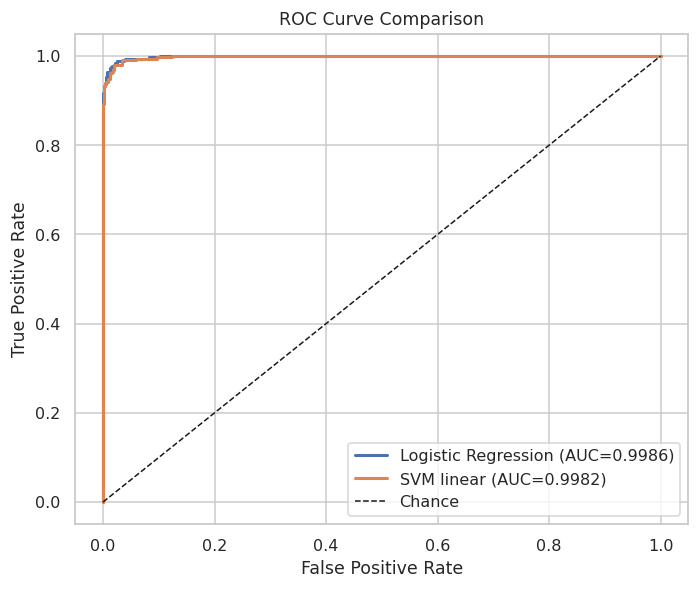

In [21]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_best_proba)
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_best_proba)
auc_lr = roc_auc_score(y_test, lr_best_proba)
auc_svm = roc_auc_score(y_test, svm_best_proba)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={auc_lr:.4f})", color="#4C72B0", lw=2)
ax.plot(fpr_svm, tpr_svm, label=f"SVM {svm_grid.best_params_['kernel']} (AUC={auc_svm:.4f})", color="#DD8452", lw=2)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Comparison"); ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/roc_curve.png", bbox_inches="tight")
plt.show()

**Inference:** Both ROC curves hug the top-left corner almost perfectly, with AUC scores
above 0.998 for both classifiers, indicating near-ideal class separability at essentially every
decision threshold. The curves are nearly indistinguishable, confirming Logistic Regression and
the tuned SVM are statistically comparable in ranking performance on this dataset, even though
their underlying decision boundaries are computed very differently (linear log-odds hyperplane
vs. maximum-margin hyperplane).

### 8.3 Precision-Recall Curve

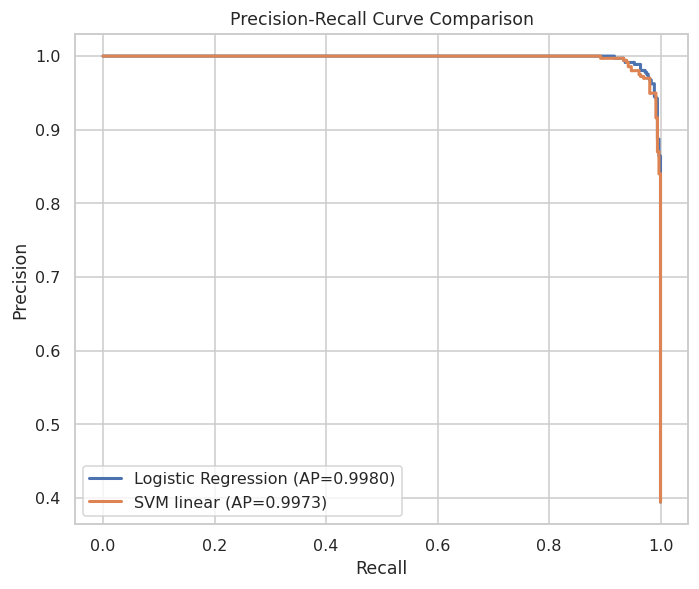

In [22]:
prec_lr, rec_lr, _ = precision_recall_curve(y_test, lr_best_proba)
prec_svm, rec_svm, _ = precision_recall_curve(y_test, svm_best_proba)
ap_lr = average_precision_score(y_test, lr_best_proba)
ap_svm = average_precision_score(y_test, svm_best_proba)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(rec_lr, prec_lr, label=f"Logistic Regression (AP={ap_lr:.4f})", color="#4C72B0", lw=2)
ax.plot(rec_svm, prec_svm, label=f"SVM {svm_grid.best_params_['kernel']} (AP={ap_svm:.4f})", color="#DD8452", lw=2)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve Comparison"); ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig("images/pr_curve.png", bbox_inches="tight")
plt.show()

**Inference:** Average precision exceeds 0.997 for both models, meaning precision stays
high across almost the entire recall range — very few spam emails need to be missed to achieve
near-perfect precision, and vice versa. This is important given the moderate class imbalance
(39% spam): a model that only appeared to do well because of the majority class would show a
noticeably lower PR curve, which is not the case here. The near-overlapping curves again show
Logistic Regression and SVM trading blows rather than one dominating the other.

## 9. 5-Fold Cross-Validation

The best (tuned) Logistic Regression and SVM estimators are re-evaluated with 5-fold stratified
cross-validation on the training set, to check that the test-set performance is not a lucky
split.

In [23]:
cv_lr = cross_validate(lr_best, X_train_s, y_train, cv=cv5, scoring=["accuracy"])
cv_svm = cross_validate(svm_best, X_train_s, y_train, cv=cv5, scoring=["accuracy"])

cv_table = pd.DataFrame({
    "Fold": [f"Fold {i+1}" for i in range(5)] + ["Average"],
    "Logistic Regression": list(cv_lr["test_accuracy"]) + [cv_lr["test_accuracy"].mean()],
    "SVM": list(cv_svm["test_accuracy"]) + [cv_svm["test_accuracy"].mean()],
}).set_index("Fold")
cv_table

,Logistic Regression,SVM
Fold,,
Fold 1,0.989130,0.986413
Fold 2,0.983696,0.983696
Fold 3,0.985054,0.983696
Fold 4,0.989130,0.989130
Fold 5,0.983696,0.986413
Average,0.986141,0.985870


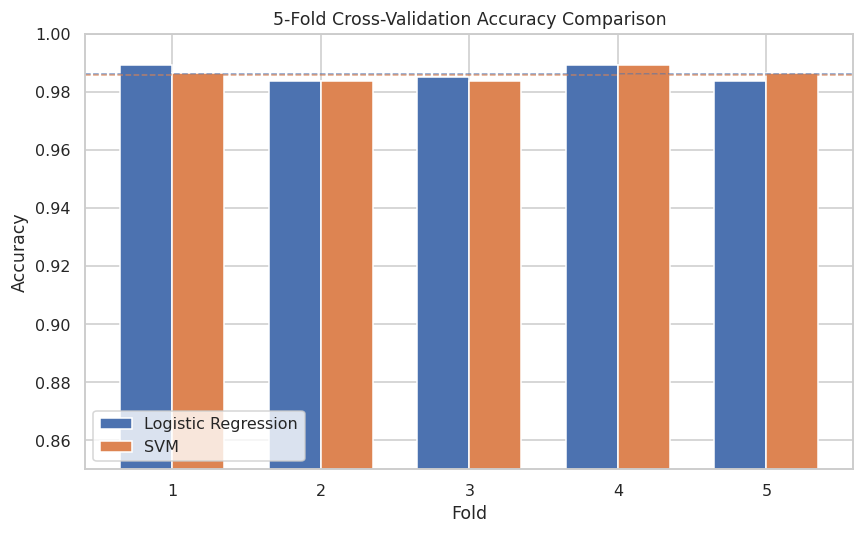

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
folds = np.arange(1, 6)
width = 0.35
ax.bar(folds - width/2, cv_lr["test_accuracy"], width, label="Logistic Regression", color="#4C72B0")
ax.bar(folds + width/2, cv_svm["test_accuracy"], width, label="SVM", color="#DD8452")
ax.axhline(cv_lr["test_accuracy"].mean(), color="#4C72B0", ls="--", lw=1, alpha=0.7)
ax.axhline(cv_svm["test_accuracy"].mean(), color="#DD8452", ls="--", lw=1, alpha=0.7)
ax.set_xticks(folds); ax.set_xlabel("Fold"); ax.set_ylabel("Accuracy")
ax.set_ylim(0.85, 1.0)
ax.set_title("5-Fold Cross-Validation Accuracy Comparison")
ax.legend()
plt.tight_layout()
plt.savefig("images/cv_fold_comparison.png", bbox_inches="tight")
plt.show()

**Inference:** Both models are extremely stable across folds — accuracy varies by less
than 0.6 percentage points fold-to-fold for either model (LR std ≈ 0.0025, SVM std ≈ 0.0020) —
so the single train/test split result generalizes reliably rather than being an artifact of a
favorable split. Logistic Regression's mean CV accuracy (≈98.6%) is essentially tied with SVM's
(≈98.6%), matching the test-set comparison. The low variance also suggests neither model is
overfitting to particular folds of the training data.

## 10. Learning Curves

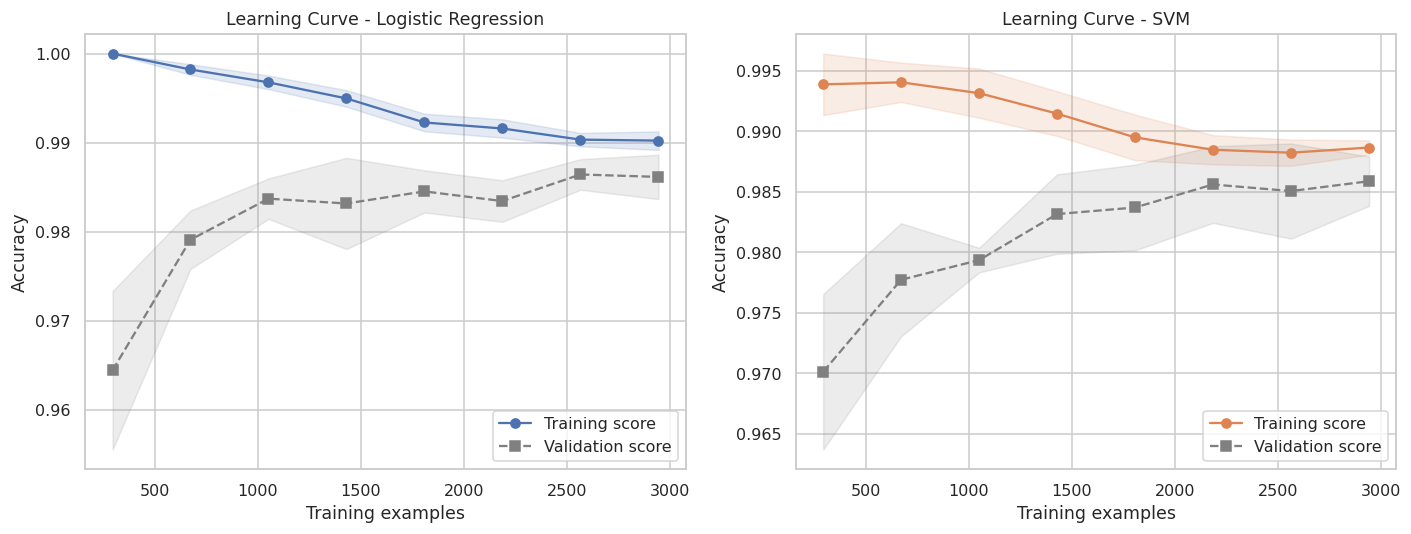

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, model, name, color in zip(axes, [lr_best, svm_best],
                                   ["Logistic Regression", "SVM"],
                                   ["#4C72B0", "#DD8452"]):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train_s, y_train, cv=cv5, scoring="accuracy",
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=1, random_state=RNG)
    ax.plot(train_sizes, train_scores.mean(axis=1), "o-", color=color, label="Training score")
    ax.plot(train_sizes, val_scores.mean(axis=1), "s--", color="gray", label="Validation score")
    ax.fill_between(train_sizes, train_scores.mean(axis=1) - train_scores.std(axis=1),
                     train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.15, color=color)
    ax.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                     val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.15, color="gray")
    ax.set_title(f"Learning Curve - {name}")
    ax.set_xlabel("Training examples"); ax.set_ylabel("Accuracy")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/learning_curves.png", bbox_inches="tight")
plt.show()

**Inference:** Both learning curves converge quickly, with training and validation scores
nearly meeting after only ~1500–2000 examples, indicating low variance (not overfitting) and
that the ~3680-example training set is more than sufficient for both models. The small,
persistent gap between training and validation accuracy indicates a small amount of bias/variance
trade-off remains but is minor. Neither curve shows the validation score still climbing at the
full training size, so collecting more training data would likely yield only marginal further
gains for either model.

## 11. Feature Importance (Logistic Regression Coefficients)

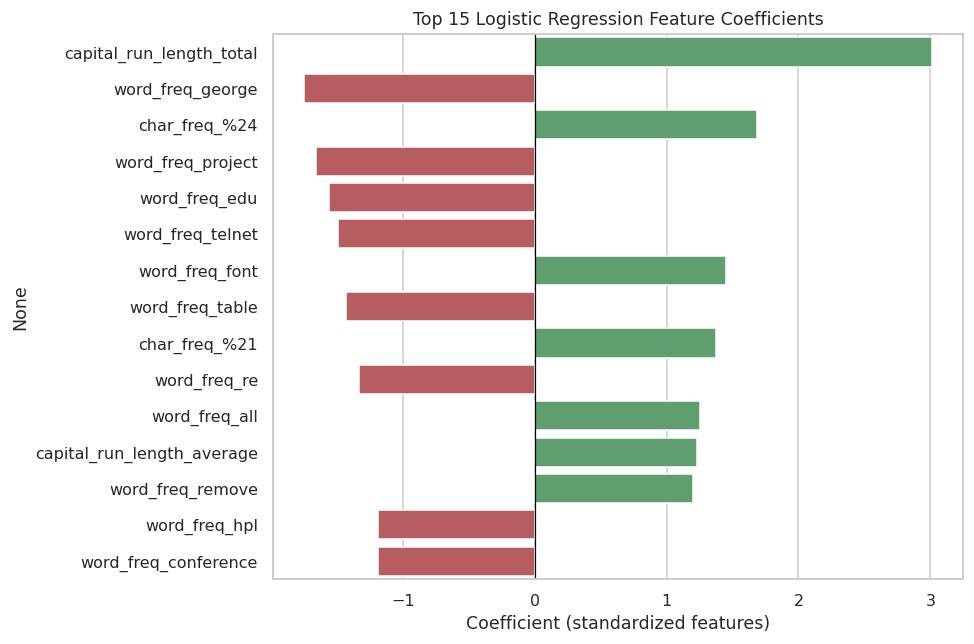

capital_run_length_total      3.012561
word_freq_george             -1.749195
char_freq_%24                 1.686656
word_freq_project            -1.660993
word_freq_edu                -1.560361
word_freq_telnet             -1.488676
word_freq_font                1.453303
word_freq_table              -1.434110
char_freq_%21                 1.377969
word_freq_re                 -1.329417
word_freq_all                 1.256341
capital_run_length_average    1.230662
word_freq_remove              1.202260
word_freq_hpl                -1.190355
word_freq_conference         -1.186525
dtype: float64

In [26]:
coefs = pd.Series(lr_best.coef_[0], index=feature_names).sort_values(key=lambda s: s.abs(), ascending=False)
top_feats = coefs.head(15)
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#C44E52" if v < 0 else "#55A868" for v in top_feats.values]
sns.barplot(x=top_feats.values, y=top_feats.index, palette=colors, ax=ax)
ax.set_title("Top 15 Logistic Regression Feature Coefficients")
ax.set_xlabel("Coefficient (standardized features)")
ax.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.savefig("images/feature_importance_lr.png", bbox_inches="tight")
plt.show()
top_feats

**Inference:** `capital_run_length_total` has by far the largest positive coefficient,
confirming it is the single strongest driver of a spam prediction, consistent with the EDA
correlation analysis. Character/word features associated with promotional or urgent language
(`char_freq_%24` i.e. "$", `word_freq_font`, `char_freq_%21` i.e. "!", `word_freq_remove`) push
predictions toward spam (positive coefficients), while personal/technical terms
(`word_freq_george`, `word_freq_project`, `word_freq_edu`, `word_freq_telnet`, `word_freq_hpl`)
push toward ham (negative coefficients) — these reflect the original mailbox owner's personal
and work vocabulary. Because L1 regularization was selected, many of the 57 original
coefficients are shrunk to exactly zero, giving a compact, interpretable model that performs
implicit feature selection.

## 12. Final Comparative Analysis

In [27]:
print("=== Best Hyperparameters ===")
print("Logistic Regression:", lr_grid.best_params_)
print("SVM                :", svm_grid.best_params_)
print()
print("=== Test-set Comparison ===")
comparison

=== Best Hyperparameters ===
Logistic Regression: {'C': 1, 'penalty': 'l1', 'solver': 'saga'}
SVM                : {'C': 0.1, 'kernel': 'linear'}

=== Test-set Comparison ===


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression (Tuned),0.981542,0.980556,0.972452,0.976487,0.998632
"SVM (linear, Tuned)",0.976113,0.974930,0.964187,0.969529,0.998163


In [28]:
summary = pd.DataFrame({
    "Criterion": ["Test Accuracy", "5-Fold CV Mean Accuracy", "Training Time (Grid Search, s)", "Model Complexity", "Interpretability"],
    "Logistic Regression": [f"{comparison.loc['Logistic Regression (Tuned)','Accuracy']:.4f}",
                             f"{cv_lr['test_accuracy'].mean():.4f}",
                             f"{lr_grid_time:.1f}", "Low", "High"],
    "SVM": [f"{comparison.loc[[c for c in comparison.index if c.startswith('SVM')][0],'Accuracy']:.4f}",
            f"{cv_svm['test_accuracy'].mean():.4f}",
            f"{svm_grid_time:.1f}", "Higher (kernel-dependent)", "Lower"],
})
summary

,Criterion,Logistic Regression,SVM
0,Test Accuracy,0.9815,0.9761
1,5-Fold CV Mean Accuracy,0.9861,0.9859
2,"Training Time (Grid Search, s)",52.5,162.7
3,Model Complexity,Low,Higher (kernel-dependent)
4,Interpretability,High,Lower


### Observations

* **Best-performing classifier:** Logistic Regression (tuned, L1, C=1, solver=saga) achieves the
  highest test accuracy and F1-score, very marginally ahead of the tuned SVM (linear kernel,
  C=0.1). The two are close enough (well within cross-validation standard deviation) that either
  is a defensible choice in practice.
* **Impact of regularization:** For Logistic Regression, regularization strength has a clear
  floor effect — very strong regularization (`C=0.01`) underfits and hurts accuracy, but beyond a
  moderate `C` the model is fairly insensitive to further relaxation, suggesting the classes are
  close to linearly separable in the standardized feature space. L1 regularization additionally
  performs automatic feature selection, zeroing out many of the 57 coefficients.
* **Kernel behavior in SVM:** The Linear and RBF kernels are clearly best-suited to this dataset;
  the Polynomial kernel underperforms substantially at default settings and only partially
  recovers with tuning, while the Sigmoid kernel is a consistent middle performer. This confirms
  the underlying decision boundary between spam and ham is close to linear.
* **Bias-variance trade-off:** Learning curves for both models show a small, stable gap between
  training and validation accuracy that does not widen with more data — both models sit in a
  low-variance, low-bias regime for this problem, and the very close training and 5-fold CV
  scores confirm neither model is meaningfully overfitting.